In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Rectangle
import time
from IPython.display import Image, display
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

In [2]:
env = gym.make('CliffWalking-v1')
n_states = env.observation_space.n
n_actions = env.action_space.n

print(f"Environnement: CliffWalking-v1")
print(f"États: {n_states} | Actions: {n_actions}")
print(f"Actions → 0:↑ 1:→ 2:↓ 3:←")

Environnement: CliffWalking-v1
États: 48 | Actions: 4
Actions → 0:↑ 1:→ 2:↓ 3:←


In [3]:
def value_iteration(env, gamma=0.9, theta=1e-6, max_iterations=5000):
    """

    Args:
        env: environnement Gymnasium
        gamma: facteur d'escompte (0.9 pour CliffWalking)
        theta: seuil de convergence
        max_iterations: nombre maximum d'itérations

    Returns:
        V: fonction de valeur optimale
        policy: politique optimale
        iterations: nombre d'itérations effectuées
    """

    n_states = env.observation_space.n
    n_actions = env.action_space.n

    # Initialisation de la fonction de valeur
    V = np.zeros(n_states)

    # Boucle principale
    for iteration in range(max_iterations):
        delta = 0
        V_new = V.copy()  # Créer une copie pour mise à jour synchrone

        for s in range(n_states):
            # Pour CliffWalking, l'état 47 (but) a une valeur de 0
            if s == 47:
                continue

            v_old = V[s]
            action_values = np.zeros(n_actions)

            # Calcul des valeurs pour chaque action
            for a in range(n_actions):
                q_value = 0
                # CliffWalking a des transitions déterministes
                # P[s][a] est une liste avec un seul élément (prob, next_state, reward, done)
                for prob, s_next, reward, done in env.unwrapped.P[s][a]:
                    q_value += prob * (reward + gamma * V[s_next])
                action_values[a] = q_value

            # Mise à jour avec la meilleure action
            V_new[s] = np.max(action_values)
            delta = max(delta, abs(v_old - V_new[s]))

        V = V_new  # Mise à jour synchrone

        # Vérification de la convergence
        if delta < theta:
            print(f"  Convergée après {iteration + 1} itérations")
            break

    # Extraction de la politique optimale
    policy = np.zeros(n_states, dtype=int)

    for s in range(n_states):
        if s == 47:  # État but, pas d'action nécessaire
            policy[s] = 0
            continue

        action_values = np.zeros(n_actions)
        for a in range(n_actions):
            q_value = 0
            for prob, s_next, reward, done in env.unwrapped.P[s][a]:
                q_value += prob * (reward + gamma * V[s_next])
            action_values[a] = q_value

        # Sélection de l'action avec la valeur maximale
        policy[s] = np.argmax(action_values)

    return V, policy, iteration + 1

In [4]:
def policy_evaluation(env, policy, gamma=0.9, theta=1e-6):
    """
    Évaluation d'une politique pour CliffWalking.
    """
    n_states = env.observation_space.n
    V = np.zeros(n_states)

    while True:
        delta = 0
        V_new = V.copy()

        for s in range(n_states):
            if s == 47:  # État but
                continue

            v_old = V[s]
            a = policy[s]

            # Calcul de la valeur selon la politique
            new_value = 0
            for prob, s_next, reward, done in env.unwrapped.P[s][a]:
                new_value += prob * (reward + gamma * V[s_next])

            V_new[s] = new_value
            delta = max(delta, abs(v_old - new_value))

        V = V_new

        if delta < theta:
            break

    return V

def policy_iteration(env, gamma=0.9, theta=1e-6, max_iterations=100):
    """
    Algorithme Policy Iteration.
    """
    n_states = env.observation_space.n
    n_actions = env.action_space.n

    # Initialisation avec une politique raisonnable (vers la droite par défaut)
    policy = np.ones(n_states, dtype=int)  # Action 1 = RIGHT par défaut

    for iteration in range(max_iterations):
        # Étape 1: Évaluation
        V = policy_evaluation(env, policy, gamma, theta)

        # Étape 2: Amélioration
        policy_stable = True

        for s in range(n_states):
            if s == 47:  # État but
                continue

            old_action = policy[s]

            # Calcul des Q-values
            action_values = np.zeros(n_actions)
            for a in range(n_actions):
                q_value = 0
                for prob, s_next, reward, done in env.unwrapped.P[s][a]:
                    q_value += prob * (reward + gamma * V[s_next])
                action_values[a] = q_value

            # Sélection de la meilleure action
            best_action = np.argmax(action_values)
            policy[s] = best_action

            if old_action != best_action:
                policy_stable = False

        if policy_stable:
            print(f"  Convergée après {iteration + 1} itérations")
            break

    return V, policy, iteration + 1

In [5]:
# EXÉCUTION DE VALUE ITERATION
print("\n--- Value Iteration ---")
start_time = time.time()
V_vi, policy_vi, iter_vi = value_iteration(env, gamma=0.9, theta=1e-6)
time_vi = time.time() - start_time
print(f"Itérations : {iter_vi} | Temps d'exécution : {time_vi:.4f} s")

# EXÉCUTION DE POLICY ITERATION
print("\n--- Policy Iteration ---")
start_time = time.time()
V_pi, policy_pi, iter_pi = policy_iteration(env, gamma=0.9, theta=1e-6)
time_pi = time.time() - start_time
print(f"Itérations : {iter_pi} | Temps d'exécution : {time_pi:.4f} s")



--- Value Iteration ---
  Convergée après 15 itérations
Itérations : 15 | Temps d'exécution : 0.0094 s

--- Policy Iteration ---
  Convergée après 15 itérations
Itérations : 15 | Temps d'exécution : 0.3259 s


In [6]:
def evaluer_politique(env, policy, n_episodes=100, max_steps=100):
    """
    Évaluation robuste d'une politique.
    """
    succes = 0
    recompenses_totales = []
    longueurs_episodes = []

    for episode in range(n_episodes):
        state, _ = env.reset()
        recompense_totale = 0
        steps = 0
        done = False

        while not done and steps < max_steps:
            action = policy[state]
            state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            recompense_totale += reward
            steps += 1

        recompenses_totales.append(recompense_totale)
        longueurs_episodes.append(steps)

        # Succès si l'agent atteint le but (état 47)
        if terminated and state == 47:
            succes += 1

    taux_succes = succes / n_episodes
    recompense_moyenne = np.mean(recompenses_totales)
    longueur_moyenne = np.mean(longueurs_episodes)

    return taux_succes, recompense_moyenne, longueur_moyenne


In [7]:
print("\n===== ÉVALUATION DES POLITIQUES =====\n")

# Value Iteration
print("→ Value Iteration")
succes_vi, reward_vi, length_vi = evaluer_politique(env, policy_vi, n_episodes=100)
print(f"  Taux de succès      : {succes_vi:.2%}")
print(f"  Récompense moyenne  : {reward_vi:.2f}")
print(f"  Longueur moyenne    : {length_vi:.1f} pas\n")

# Policy Iteration
print("→ Policy Iteration")
succes_pi, reward_pi, length_pi = evaluer_politique(env, policy_pi, n_episodes=100)
print(f"  Taux de succès      : {succes_pi:.2%}")
print(f"  Récompense moyenne  : {reward_pi:.2f}")
print(f"  Longueur moyenne    : {length_pi:.1f} pas")



===== ÉVALUATION DES POLITIQUES =====

→ Value Iteration
  Taux de succès      : 100.00%
  Récompense moyenne  : -13.00
  Longueur moyenne    : 13.0 pas

→ Policy Iteration
  Taux de succès      : 100.00%
  Récompense moyenne  : -13.00
  Longueur moyenne    : 13.0 pas


In [8]:
# Cellule 7: Visualisation des politiques
def visualiser_politique(policy, n_rows=4, n_cols=12, titre="Politique"):
    """
    Visualisation améliorée des politiques.
    """
    symbols = ['↑', '→', '↓', '←']

    print(f"\n{titre}:")
    print("-" * 50)

    for i in range(n_rows):
        print("  ", end="")
        for j in range(n_cols):
            state = i * n_cols + j
            if state == 36:
                print("[S]", end=" ")
            elif state == 47:
                print("[G]", end=" ")
            elif 37 <= state <= 46:
                print("[C]", end=" ")
            else:
                print(f"[{symbols[policy[state]]}]", end=" ")
        print()
    print()

# Visualisation des politiques
visualiser_politique(policy_vi, titre="Politique - Value Iteration")
visualiser_politique(policy_pi, titre="Politique - Policy Iteration")


Politique - Value Iteration:
--------------------------------------------------
  [→] [→] [→] [→] [→] [→] [→] [→] [→] [→] [→] [↓] 
  [→] [→] [→] [→] [→] [→] [→] [→] [→] [→] [→] [↓] 
  [→] [→] [→] [→] [→] [→] [→] [→] [→] [→] [→] [↓] 
  [S] [C] [C] [C] [C] [C] [C] [C] [C] [C] [C] [G] 


Politique - Policy Iteration:
--------------------------------------------------
  [→] [→] [→] [→] [→] [→] [→] [→] [→] [→] [→] [↓] 
  [→] [→] [→] [→] [→] [→] [→] [→] [→] [→] [→] [↓] 
  [→] [→] [→] [→] [→] [→] [→] [→] [→] [→] [→] [↓] 
  [S] [C] [C] [C] [C] [C] [C] [C] [C] [C] [C] [G] 



 Graphique sauvegardé: comparaison_cliffwalking.png


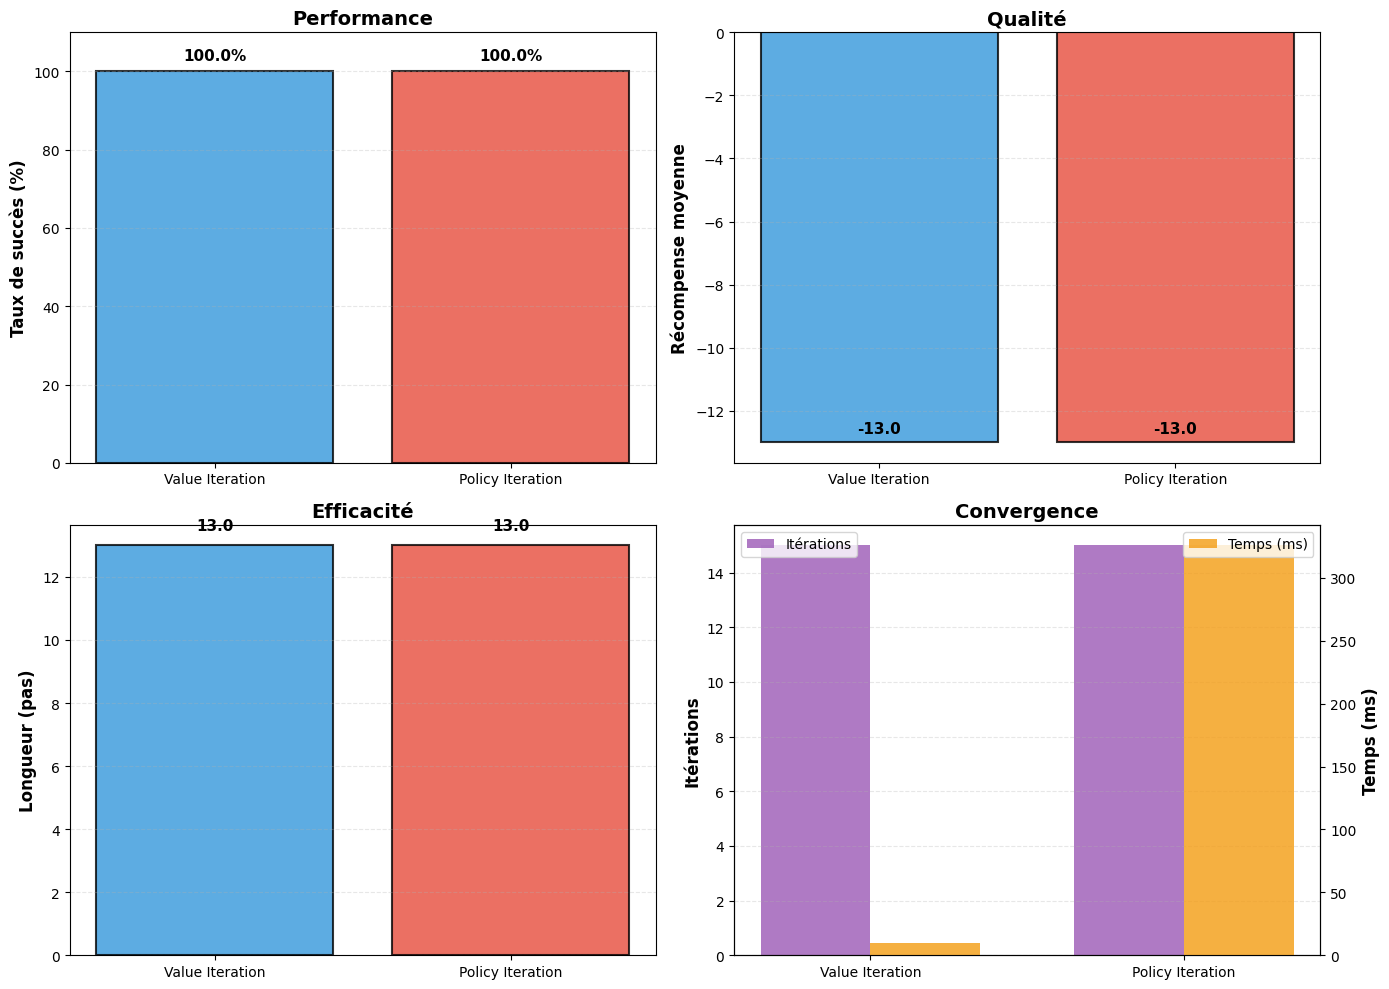

In [9]:

# Graphiques de comparaison
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
labels = ['Value Iteration', 'Policy Iteration']
couleurs = ['#3498db', '#e74c3c']

# 1️ Taux de succès
axes[0, 0].bar(labels, [succes_vi*100, succes_pi*100], color=couleurs, alpha=0.8, edgecolor='black', linewidth=1.5)
axes[0, 0].set_ylabel("Taux de succès (%)", fontsize=12, fontweight='bold')
axes[0, 0].set_title("Performance", fontsize=14, fontweight='bold')
axes[0, 0].set_ylim(0, 110)
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.3)
for i, v in enumerate([succes_vi*100, succes_pi*100]):
    axes[0, 0].text(i, v+3, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=11)

# 2️ Récompense moyenne
axes[0, 1].bar(labels, [reward_vi, reward_pi], color=couleurs, alpha=0.8, edgecolor='black', linewidth=1.5)
axes[0, 1].set_ylabel("Récompense moyenne", fontsize=12, fontweight='bold')
axes[0, 1].set_title("Qualité", fontsize=14, fontweight='bold')
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.3)
for i, v in enumerate([reward_vi, reward_pi]):
    axes[0, 1].text(i, v + 0.3, f"{v:.1f}", ha='center', fontweight='bold', fontsize=11)

# 3️ Longueur moyenne
axes[1, 0].bar(labels, [length_vi, length_pi], color=couleurs, alpha=0.8, edgecolor='black', linewidth=1.5)
axes[1, 0].set_ylabel("Longueur (pas)", fontsize=12, fontweight='bold')
axes[1, 0].set_title("Efficacité", fontsize=14, fontweight='bold')
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.3)
for i, v in enumerate([length_vi, length_pi]):
    axes[1, 0].text(i, v+0.5, f"{v:.1f}", ha='center', fontweight='bold', fontsize=11)

# 4️ Convergence : Itérations vs Temps
x = np.arange(2)
width = 0.35
ax2 = axes[1, 1].twinx()

bars1 = axes[1, 1].bar(x - width/2, [iter_vi, iter_pi], width, label='Itérations', color='#9b59b6', alpha=0.8)
bars2 = ax2.bar(x + width/2, [time_vi*1000, time_pi*1000], width, label='Temps (ms)', color='#f39c12', alpha=0.8)

axes[1, 1].set_ylabel("Itérations", fontsize=12, fontweight='bold')
ax2.set_ylabel("Temps (ms)", fontsize=12, fontweight='bold')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(labels)
axes[1, 1].set_title("Convergence", fontsize=14, fontweight='bold')
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.3)
axes[1, 1].legend(loc='upper left')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig("comparaison_cliffwalking.png", dpi=300, bbox_inches='tight')
print(" Graphique sauvegardé: comparaison_cliffwalking.png")
plt.show()


In [10]:
# Génération des trajectoires et animations
from matplotlib.patches import Rectangle
from matplotlib import animation

def generer_trajectoire(env, policy, max_steps=50):
    """Génère une trajectoire complète pour un épisode"""
    state, _ = env.reset()
    trajectoire = [state]
    done = False
    steps = 0

    while not done and steps < max_steps:
        action = policy[state]
        state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        trajectoire.append(state)
        steps += 1

        if done:
            break
    return trajectoire

def creer_animation(trajectoire, titre="Trajectoire", filename="trajectoire.gif"):
    """Crée un GIF animé de la trajectoire"""
    fig, ax = plt.subplots(figsize=(12, 4))

    def update(frame):
        ax.clear()
        for i in range(4):
            for j in range(12):
                state = i * 12 + j
                if state == 36:          # Départ
                    color, label = '#3498db', 'S'
                elif state == 47:        # But
                    color, label = '#2ecc71', 'G'
                elif 37 <= state <= 46:  # Falaise
                    color, label = '#e74c3c', 'C'
                elif state == trajectoire[frame]:  # Agent
                    color, label = '#f39c12', '★'
                elif state in trajectoire[:frame]: # Chemin parcouru
                    color, label = '#95a5a6', '·'
                else:
                    color, label = 'white', ''

                rect = Rectangle((j, 3-i), 1, 1, linewidth=2, edgecolor='black', facecolor=color)
                ax.add_patch(rect)

                if label:
                    ax.text(j+0.5, 3.5-i, label, ha='center', va='center',
                            fontsize=14, fontweight='bold', color='white' if color != 'white' else 'black')

        ax.set_xlim(0, 12)
        ax.set_ylim(0, 4)
        ax.set_aspect('equal')
        ax.axis('off')
        ax.set_title(f"{titre} - Étape {frame}/{len(trajectoire)-1}", fontsize=14, fontweight='bold', pad=20)

        # Légende
        legend_labels = [
            plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#3498db', markersize=10, label='Départ (S)'),
            plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#2ecc71', markersize=10, label='But (G)'),
            plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#e74c3c', markersize=10, label='Falaise (C)'),
            plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#f39c12', markersize=10, label='Agent (★)'),
            plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#95a5a6', markersize=10, label='Chemin parcouru')
        ]
        ax.legend(handles=legend_labels, loc='upper left', bbox_to_anchor=(1, 1), fontsize=10, framealpha=0.9)

    anim = animation.FuncAnimation(fig, update, frames=len(trajectoire), interval=300, repeat=True)
    anim.save(filename, writer='pillow', fps=3, dpi=100)
    plt.close()
    return anim




In [11]:
# Génération et sauvegarde des animations
print("GÉNÉRATION DES ANIMATIONS")

# Value Iteration
traj_vi = generer_trajectoire(env, policy_vi)
print(f"Trajectoire Value Iteration : {len(traj_vi)} étapes")
anim_vi = creer_animation(traj_vi, "Value Iteration", "value_iteration.gif")
print("Animation sauvegardée : value_iteration.gif")

# Policy Iteration
traj_pi = generer_trajectoire(env, policy_pi)
print(f"Trajectoire Policy Iteration : {len(traj_pi)} étapes")
anim_pi = creer_animation(traj_pi, "Policy Iteration", "policy_iteration.gif")
print("Animation sauvegardée : policy_iteration.gif")


GÉNÉRATION DES ANIMATIONS
Trajectoire Value Iteration : 14 étapes
Animation sauvegardée : value_iteration.gif
Trajectoire Policy Iteration : 14 étapes
Animation sauvegardée : policy_iteration.gif
